# Tracing a TGF-beta fibrosis response in one AnnNet object

TGF-beta stimulation of human kidney PDGFRβ+ mesenchymal cells produces a timed
fibrosis response. This notebook asks which responsive signaling, regulatory,
complex and metabolic contexts line up around that matrix-remodeling program.

The time course comes from the multi-omics study of Tüchler et al. (2025): the
cells were profiled by transcriptomics, proteomics, phosphoproteomics and
secretomics at several time points after TGF-beta stimulation.

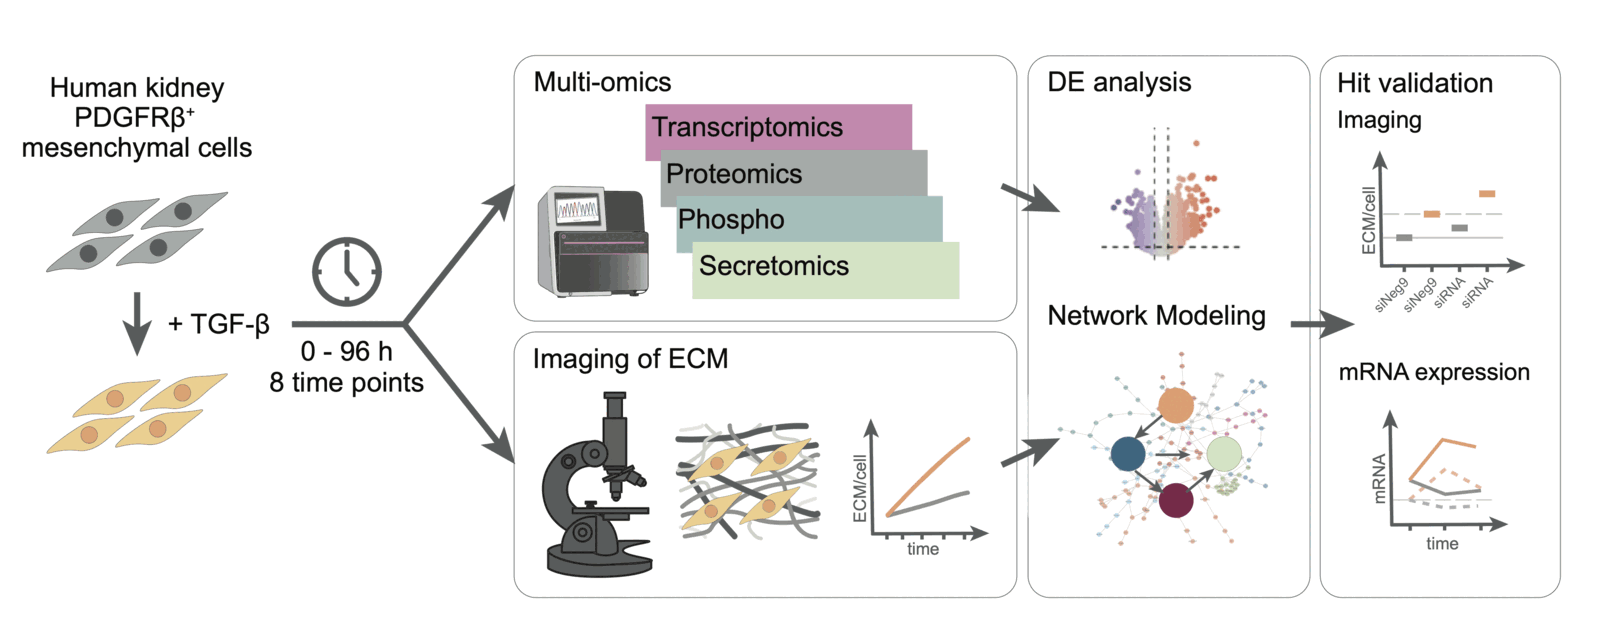

*Study overview from Tüchler N, Burtscher ML, et al.
[Dynamic multi-omics and mechanistic modeling approach uncovers novel mechanisms of kidney fibrosis progression](https://doi.org/10.1038/s44320-025-00116-2).
Molecular Systems Biology 21, 1030–1065 (2025).
[CC BY 4.0](https://creativecommons.org/licenses/by/4.0/).*

The graph combines [OmniPath](https://omnipathdb.org/) signaling,
[DoRothEA](https://saezlab.github.io/dorothea/) regulation, OmniPath complexes
and the [Human-GEM](https://github.com/SysBioChalmers/Human-GEM) metabolic model
in one AnnNet object. The same object is then used for biological joins,
receptor-to-effector paths, [Cytoscape](https://cytoscape.org/) export and
late-response forecasting with [PyTorch Geometric](https://pyg.org/).

Two aspects carry the experiment: `mechanism` and `time`. A node-layer such as
`(prot:COL1A1, signaling, 24h)` means COL1A1 is represented as a responsive
protein in the signaling layer at 24h.

To run this notebook, create the environment from
[`tgfb-fibrosis.yml`](environments/tgfb-fibrosis.yml). The notebook
also needs prepared input files in `data/`. See
[Reproduce a tutorial](index.md#reproduce-a-tutorial).

In [ ]:
import json
import time
import warnings
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl

import annnet as an

DATA, OUT = Path('data'), Path('outputs')
OUT.mkdir(exist_ok=True)
SNAPSHOT = OUT / 'uc2.annnet'

SEED = 7
BASELINE = '0h'
TIMES = ('1h', '12h', '24h', '48h', '72h', '96h')
MECHANISMS = ('signaling', 'regulatory')
MIN_FRACTION, MIN_HITS = 0.5, 2
RECEPTORS = ('TGFB1', 'TGFBR1', 'TGFBR2')
EFFECTORS = (
    'COL1A1',
    'COL1A2',
    'COL3A1',
    'FN1',
    'ACTA2',
    'SERPINE1',
    'CCN2',
    'TAGLN',
    'TIMP1',
    'LOX',
    'THBS1',
    'TNC',
    'ITGB1',
    'MMP2',
    'VIM',
    'SMAD7',
    'JUNB',
    'ID1',
)
FAMILIES = ('signaling', 'regulatory', 'coupling_translation', 'coupling_time')

## Build the graph

The first part builds one AnnNet object from the time course and four sources of
prior knowledge.

### The responsive gate

One gate defines the universe: a gene symbol enters a time layer only where the
study calls it differential at that timepoint. No fold-change floor, so the
early layers stay populated.

In [2]:
measurements = pl.read_parquet(DATA / 'measured.parquet')
responsive = pl.read_parquet(DATA / 'responsive.parquet').select('symbol', 'time', 'best_logFC')

measured_symbols = set(measurements['symbol'])
responsive_at = {
    t: set(group['symbol']) for t, group in responsive.to_pandas().groupby('time', observed=True)
}
logfc_at = {(r.symbol, r.time): r.best_logFC for r in responsive.to_pandas().itertuples()}

print(f'measured universe: {len(measured_symbols):,} symbols')
print('responsive per timepoint:', {t: len(responsive_at[t]) for t in TIMES})

measured universe: 14,966 symbols
responsive per timepoint: {'1h': 529, '12h': 2762, '24h': 3297, '48h': 4464, '72h': 5078, '96h': 7129}


### The aspect grid

The two aspects and their elementary layers are declared in the constructor.
The layer space is their product, so every vertex placement below names a
coordinate. `anet.layers.set_aspects(...)` does the same thing after the fact.


In [3]:
anet = an.AnnNet(
    directed=True,
    aspects={
        'mechanism': ['signaling', 'regulatory', 'metabolic'],
        'time': [BASELINE, *TIMES],
    },
)
anet.history.enable(True)
anet.history.snapshot('init')

print('aspects:', anet.layers.list_aspects())
print('elementary layers:', anet.layers.list_layers())

aspects: ('mechanism', 'time')
elementary layers: {'mechanism': ['metabolic', 'regulatory', 'signaling'], 'time': ['0h', '12h', '1h', '24h', '48h', '72h', '96h']}


### Prior knowledge

The signaling prior is read from the cached CX2 backbone. DoRothEA confidence A/B
supplies the regulatory prior.


In [4]:
cx2_backbone = json.loads((DATA / 'signaling.cx2').read_text())
node_symbol = {
    node['id']: node['v'].get('gene_symbol')
    for section in cx2_backbone
    for node in section.get('nodes', [])
}

signaling_pairs = []
for section in cx2_backbone:
    for edge in section.get('edges', []):
        attrs = edge.get('v', {})
        if attrs.get('edge_kind') != 'signaling':
            continue
        source, target = node_symbol.get(edge['s']), node_symbol.get(edge['t'])
        if source and target:
            signaling_pairs.append((source, target, float(attrs.get('weight', 0.0))))


def edge_sign(stimulation, inhibition):
    return (
        1.0 if stimulation and not inhibition else -1.0 if inhibition and not stimulation else 0.0
    )


dorothea = pl.read_csv(DATA / 'dorothea.tsv', separator='	', infer_schema_length=5000)
regulatory_pairs = [
    (
        r['source_genesymbol'],
        r['target_genesymbol'],
        edge_sign(r['is_stimulation'], r['is_inhibition']),
    )
    for r in dorothea.iter_rows(named=True)
]
tf_symbols = set(dorothea['source_genesymbol'])
print(f'prior knowledge: {len(signaling_pairs):,} signaling, {len(regulatory_pairs):,} regulatory')

prior knowledge: 31,898 signaling, 15,267 regulatory


### Responsive layers: signaling and regulatory

For each mechanism, walk the six timepoints and keep only the edges whose
endpoints are both responsive then — a pure 0-hop restriction on the gate. The
same protein therefore appears once per timepoint it responds in, as a distinct
*supra-node* `(vertex, mechanism, time)`.


In [5]:
def add_time_layers(anet, mechanism, pairs, prefix, kind):
    """Place responsive-gated supra-nodes and edges for one mechanism, per timepoint.

    Returns the {(symbol, time)} placed, which the coupling step consumes.
    """
    placed = set()
    for t in TIMES:
        active = responsive_at[t]
        kept = [(a, b, w) for a, b, w in pairs if a in active and b in active]
        symbols = {v for a, b, _ in kept for v in (a, b)}
        anet.add_nodes(
            [{'node_id': f'{prefix}{v}', 'gene_symbol': v, 'kind': kind} for v in sorted(symbols)],
            layer=(mechanism, t),
        )
        anet.add_edges(
            [
                {
                    'source': (f'{prefix}{a}', (mechanism, t)),
                    'target': (f'{prefix}{b}', (mechanism, t)),
                    'weight': w,
                    'edge_kind': mechanism,
                }
                for a, b, w in kept
            ],
            default_edge_directed=True,
        )
        placed |= {(v, t) for v in symbols}
    return placed


signaling_placed = add_time_layers(anet, 'signaling', signaling_pairs, 'prot:', 'protein')
regulatory_placed = add_time_layers(anet, 'regulatory', regulatory_pairs, 'gene:', 'gene')
anet.history.snapshot('after_response')

# `layer_node_set` and `layer_edge_set` read the nodes and the intra-layer edges
# of one layer from the graph.
layer_sets = (('|N|', anet.layers.layer_node_set), ('|E|', anet.layers.layer_edge_set))
topology = pd.DataFrame(
    {
        f'{mechanism} {label}': [len(layer_set((mechanism, t))) for t in TIMES]
        for mechanism in MECHANISMS
        for label, layer_set in layer_sets
    },
    index=list(TIMES),
)
topology

,signaling |N|,signaling |E|,regulatory |N|,regulatory |E|
1h,105,132,116,158
12h,813,1714,513,838
24h,1125,2643,750,1346
48h,1645,4858,1063,2044
72h,1950,5961,1221,2184
96h,2974,10884,1840,3592


### Interlayer coupling

Two families, and the distinction between them is the whole point of having two
aspects.

**Time coupling** is *ordinal*: it links the same entity at consecutive
timepoints, `(v, mech, tᵢ) → (v, mech, tᵢ₊₁)`, wherever it is responsive in
both. Time runs one way, so these edges are **directed**.

**Translation coupling** is *categorical*: it links a responsive gene to its
protein inside one timepoint, `(v, regulatory, t) — (v, signaling, t)`. This is
an identity correspondence between two readings of the same entity, not a
reaction, so it is **undirected** — which is also what makes the causal chain
receptor → TF protein → TF-as-regulator → target genes traversable in the
propagation section.


In [6]:
def at(placed, t):
    """Symbols placed in layer `t`."""
    return {v for v, tt in placed if tt == t}


time_edges = [
    {
        'edge_id': f'time:{mechanism}:{v}:{a}->{b}',
        'edge_kind': 'coupling_time',
        'weight': 1.0,
        'source': (f'{prefix}{v}', (mechanism, a)),
        'target': (f'{prefix}{v}', (mechanism, b)),
    }
    for mechanism, prefix, placed in [
        ('signaling', 'prot:', signaling_placed),
        ('regulatory', 'gene:', regulatory_placed),
    ]
    for a, b in zip(TIMES, TIMES[1:], strict=False)
    for v in sorted(at(placed, a) & at(placed, b))
]

translation_edges = [
    {
        'edge_id': f'trans:{v}:{t}',
        'edge_kind': 'coupling_translation',
        'weight': 1.0,
        'source': (f'gene:{v}', ('regulatory', t)),
        'target': (f'prot:{v}', ('signaling', t)),
    }
    for t in TIMES
    for v in sorted(at(regulatory_placed, t) & at(signaling_placed, t))
]

anet.add_edges(time_edges, default_edge_directed=True)
anet.add_edges(translation_edges, default_edge_directed=False)
anet.history.snapshot('after_coupling')
print(f'time-coupling edges        (directed)  : {len(time_edges):,}')
print(f'translation-coupling edges (undirected): {len(translation_edges):,}')

time-coupling edges        (directed)  : 7,644
translation-coupling edges (undirected): 3,314


### Baseline scaffold: two kinds of hyperedge

Complexes and metabolism are time-invariant, so they live in the `0h` layer.
Each OmniPath complex becomes **one undirected hyperedge** over its subunits —
a single incidence-matrix column, not a clique of pairwise edges. One
`from_sbml` call reads Human-GEM: reactions become **signed directed
hyperedges** carrying stoichiometry, and compartments become slices.

`from_sbml` adds metabolite and boundary vertices without a `kind`, so they are
typed here for the PyG export further down.


In [7]:
complexes = pl.read_csv(DATA / 'omnipath_complexes.tsv', separator='\t', infer_schema_length=5000)
complex_specs, members = [], set()
for row in complexes.iter_rows(named=True):
    subunits = (row['components_genesymbols'] or '').split('_')
    if subunits == [''] or not set(subunits) <= measured_symbols:
        continue
    members.update(f'prot:{s}' for s in subunits)
    complex_specs.append(
        {
            'edge_id': f'cpx:{row["name"]}',
            'edge_kind': 'complex',
            'weight': 1.0,
            'members': [(f'prot:{s}', ('signaling', BASELINE)) for s in subunits],
        }
    )

anet.add_nodes(
    [
        {'node_id': v, 'kind': 'protein', 'gene_symbol': v.removeprefix('prot:')}
        for v in sorted(members)
    ],
    layer=('signaling', BASELINE),
)
anet.add_edges(complex_specs, layer=('signaling', BASELINE))
anet.history.snapshot('after_complex')

an.from_sbml(
    str(DATA / 'Human-GEM.xml'),
    graph=anet,
    slice='metabolic',
    layer=('metabolic', BASELINE),
    preserve_stoichiometry=True,
)
untyped = (
    anet.attrs.table('nodes', derived=True)
    .filter(pl.col('kind').is_null())
    .get_column('node_id')
    .to_list()
)
anet.attrs.update(
    'nodes', {v: {'kind': 'boundary' if v.startswith('__') else 'metabolite'} for v in untyped}
)
anet.history.snapshot('after_metabolic')

# Complex names are not unique in OmniPath, so same-named entries share an edge_id.
n_complex = sum(str(e).startswith('cpx:') for e in anet.hyperedge_definitions)
print(f'complex hyperedges  : {n_complex:,} (from {len(complex_specs):,} specs)')
print(f'reaction hyperedges : {len(anet.hyperedge_definitions) - n_complex:,}')
print(f'|V| = {anet.global_count("nodes"):,}   |E| = {anet.global_count("edges"):,}')

complex hyperedges  : 3,446 (from 7,991 specs)
reaction hyperedges : 12,971
|V| = 19,580   |E| = 63,729


### Organelle slices

A slice is a **membership overlay** on the shared graph: it duplicates no
topology, where the usual alternative keeps one graph object per compartment.
Compartments are time-invariant, so a protein joins its organelle regardless of
when it responds. The cross-compartment query below reads the membership back
out of the graph.


In [8]:
ORGANELLES = {
    'Mitochondria': 'mitochondria',
    'Nucleus': 'nucleus',
    'Nucleoplasm': 'nucleus',
    'Nucleoli': 'nucleus',
    'Nuclear membrane': 'nucleus',
    'Endoplasmic reticulum': 'er',
    'Golgi apparatus': 'golgi',
    'Lysosome': 'lysosome',
    'Cytosol': 'cytosol',
    'Cytoplasm': 'cytosol',
    'Plasma membrane': 'plasma_membrane',
    'Cell Junctions': 'plasma_membrane',
    'Peroxisome': 'peroxisome',
    'Vesicles': 'vesicles',
}

hpa = pl.read_csv(DATA / 'proteinatlas.tsv', separator='\t', infer_schema_length=10000)
location = dict(
    zip(hpa['Gene'].to_list(), hpa['Subcellular main location'].to_list(), strict=False)
)


def organelle_of(symbol):
    """Organelle slice name for a gene symbol; cytosol by default."""
    text = location.get(symbol) or ''
    return next(
        (name for key, name in ORGANELLES.items() if key.lower() in text.lower()), 'cytosol'
    )


proteins = anet.attrs.table('nodes', derived=True).filter(
    pl.col('node_id').str.starts_with('prot:')
)
organelle = {r['node_id']: organelle_of(r['gene_symbol']) for r in proteins.iter_rows(named=True)}

for name in sorted(set(organelle.values())):
    vids = {v for v, o in organelle.items() if o == name}
    anet.slices.add(name, role='organelle')
    for v in sorted(vids):
        anet.slices.add_node_to_slice(name, v)
    anet.slices.add_edges(
        name,
        [e for e, (s, t, _) in anet.edge_definitions.items() if s[0] in vids and t[0] in vids],
    )
anet.history.snapshot('after_slices')

print(f'{len(set(organelle.values()))} organelle slices over {len(organelle):,} proteins')
print(Counter(organelle.values()).most_common())

9 organelle slices over 8,999 proteins
[('cytosol', 3465), ('nucleus', 3249), ('mitochondria', 609), ('plasma_membrane', 513), ('vesicles', 489), ('golgi', 369), ('er', 277), ('lysosome', 17), ('peroxisome', 11)]


## Biological joins

The first readouts look for structure around the fibrotic program before any
shortest-path or learning model is used.


In [9]:
edge_kind = dict(zip(anet.E.ids, anet.E.column('edge_kind'), strict=False))
E = pd.DataFrame(
    [(e, s[0], *s[1], t[0], *t[1], edge_kind[e]) for e, (s, t, _) in anet.edge_definitions.items()],
    columns=['edge_id', 'src', 'src_mech', 'src_time', 'tgt', 'tgt_mech', 'tgt_time', 'edge_kind'],
)
intra = E[(E.src_mech == E.tgt_mech) & (E.src_time == E.tgt_time)]

subunits = {
    e: {m[0].removeprefix('prot:') for m in spec['members']}
    for e, spec in anet.hyperedge_definitions.items()
    if str(e).startswith('cpx:')
}

print(E.edge_kind.value_counts().to_string())
print(f'\nintra-layer {len(intra):,} (both endpoints in one (mechanism, time) layer)')
print(f'interlayer  {len(E) - len(intra):,} (the two coupling families)')
print(f'complexes   {len(subunits):,} hyperedges')

edge_kind
signaling               26192
regulatory              10162
coupling_time            7644
coupling_translation     3314

intra-layer 36,354 (both endpoints in one (mechanism, time) layer)
interlayer  10,958 (the two coupling families)
complexes   3,446 hyperedges


### Which TFs organize responsive protein complexes?

For each timepoint, a TF is paired with an OmniPath complex when its responsive
DoRothEA targets cover enough measured subunits of that complex. This highlights
candidate regulatory programs whose targets appear as coordinated protein
machinery, not just individual genes. The table shows the latest
timepoint, with the programs that contain fibrosis effectors first.


In [10]:
regulatory = intra[intra.edge_kind == 'regulatory'].assign(
    src_symbol=lambda d: d.src.str.removeprefix('gene:'),
    tgt_symbol=lambda d: d.tgt.str.removeprefix('gene:'),
)
big_complexes = {e: g for e, g in subunits.items() if len(g) >= 3}


def coregulated(targets_of, complex_sets=big_complexes):
    """(TF, complex) pairs whose targets cover enough of the complex."""
    return {
        (tf, complex_id)
        for complex_id, genes in complex_sets.items()
        for tf, targets in targets_of.items()
        if len(genes & targets) >= MIN_HITS and len(genes & targets) / len(genes) >= MIN_FRACTION
    }


targets_at = {
    t: regulatory[regulatory.src_time == t].groupby('src_symbol')['tgt_symbol'].apply(set)
    for t in TIMES
}
pairs_at = {t: coregulated(targets_at[t]) for t in TIMES}
print('responsive TF-complex programs:', {t: len(p) for t, p in pairs_at.items()})

late_programs = pd.DataFrame(sorted(pairs_at[TIMES[-1]]), columns=['tf', 'complex_id'])
late_programs['fibrosis_subunits'] = late_programs.complex_id.map(
    lambda complex_id: ','.join(sorted(big_complexes[complex_id] & set(EFFECTORS)))
)
late_programs = late_programs.sort_values(
    ['fibrosis_subunits', 'tf', 'complex_id'], ascending=[False, True, True], ignore_index=True
)
late_programs.head(10)

responsive TF-complex programs: {'1h': 3, '12h': 53, '24h': 63, '48h': 130, '72h': 132, '96h': 278}


,tf,complex_id,fibrosis_subunits
0,JUND,cpx:ITGAV-ITGB3-THBS1 complex,THBS1
1,SP1,cpx:Ubiquitin E3 ligase (SMAD7-SMURF1) - TGF(b...,SMAD7
2,SP1,"cpx:Ubiquitin E3 ligase (SMURF2, SMAD7) - TGF(...",SMAD7
3,E2F1,cpx:ITGA3-ITGB1-THBS1 complex,"ITGB1,THBS1"
4,E2F1,cpx:ITGA4-ITGB1-THBS1 complex,"ITGB1,THBS1"
5,MYC,cpx:ITGA3-ITGB1-THBS1 complex,"ITGB1,THBS1"
6,MYC,cpx:ITGA4-ITGB1-THBS1 complex,"ITGB1,THBS1"
7,MYC,cpx:ITGA3-ITGB1-BSG complex,ITGB1
8,MYC,cpx:ITGA6-ITGB1-CD151 complex,ITGB1
9,MYC,cpx:ITGA6-ITGB1-CYR61 complex,ITGB1


### Where does responsive signaling cross compartments?

Organelle slices turn each responsive signaling edge into a compartment-to-
compartment observation. The table asks whether the signaling layer is mostly
local or whether the response increasingly crosses organelle boundaries, which is
relevant for receptor, cytosolic kinase and nuclear TF handoffs.


In [11]:
organelle_of_vertex = {
    v: name
    for name in anet.slices.list(include_default=False)
    if anet.attrs.row('slices', name).get('role') == 'organelle'
    for v in anet.slices.nodes(name)
}
print(
    f'{len(set(organelle_of_vertex.values()))} organelle slices covering '
    f'{len(organelle_of_vertex):,} proteins\n'
)

signaling = intra[intra.edge_kind == 'signaling'].assign(
    src_organelle=lambda d: d.src.map(organelle_of_vertex),
    tgt_organelle=lambda d: d.tgt.map(organelle_of_vertex),
)
cross = signaling[signaling.src_organelle != signaling.tgt_organelle]

per_time = pd.DataFrame(
    {
        'signaling': signaling.groupby('src_time').size().reindex(TIMES, fill_value=0),
        'cross_compartment': cross.groupby('src_time').size().reindex(TIMES, fill_value=0),
    }
)
per_time['fraction'] = (per_time.cross_compartment / per_time.signaling).round(3)
per_time

9 organelle slices covering 8,999 proteins



,signaling,cross_compartment,fraction
src_time,,,
1h,132,81,0.614
12h,1714,1166,0.680
24h,2643,1770,0.670
48h,4858,3139,0.646
72h,5961,3793,0.636
96h,10884,6537,0.601


### Which complexes sit near the responsive signaling backbone?

Each baseline complex is scored by the signaling degree of its measured subunits
across the time-resolved signaling layers. Complexes containing fibrosis effectors
are kept visible in the same table, so the query can point to machinery that is
both topologically exposed and biologically on-theme.


In [12]:
degree = (
    pd.concat([signaling.src.value_counts(), signaling.tgt.value_counts()], axis=1)
    .fillna(0)
    .sum(axis=1)
)
hubs = pd.DataFrame(
    [
        {
            'complex_id': complex_id,
            'n_subunits': len(genes),
            'signaling_degree': float(sum(degree.get(f'prot:{g}', 0) for g in genes)),
            'fibrosis_subunits': ','.join(sorted(genes & set(EFFECTORS))),
        }
        for complex_id, genes in subunits.items()
    ]
).sort_values(
    ['fibrosis_subunits', 'signaling_degree'], ascending=[False, False], ignore_index=True
)
hubs.head(5)

,complex_id,n_subunits,signaling_degree,fibrosis_subunits
0,cpx:pERK-vimentin-KPNA2 complex,3,498.0,VIM
1,cpx:Tenascin-C complex,1,42.0,TNC
2,cpx:ITGAV-ITGB3-THBS1 complex,3,295.0,THBS1
3,cpx:Thrombospondin 1 complex,1,49.0,THBS1
4,cpx:Ubiquitin E3 ligase (SMAD7-SMURF1) - TGF(b...,4,367.0,SMAD7


## Receptor-to-effector paths

Starting from TGF-beta receptors at 1h, which fibrosis effectors become
reachable, through which intermediates, and at what timepoint?


In [13]:
t0 = time.perf_counter()
with warnings.catch_warnings():
    warnings.simplefilter('ignore', RuntimeWarning)
    flow = anet.ig.backend()

keys = [str(n) for n in flow.vs['name']]
flow = flow.permute_vertices(np.argsort(keys, kind='stable').tolist())
names = flow.vs['name']
supra = {n: i for i, n in enumerate(names) if isinstance(n, tuple)}
seeds = [
    supra[(f'prot:{r}', ('signaling', TIMES[0]))]
    for r in RECEPTORS
    if (f'prot:{r}', ('signaling', TIMES[0])) in supra
]

print(
    f'AnnNet -> igraph: {time.perf_counter() - t0:.1f}s '
    f'({flow.vcount():,} vertices, {flow.ecount():,} arcs)'
)
print(f'seeds: {[names[i] for i in seeds]}')
print(Counter(flow.es['edge_kind']).most_common())

AnnNet -> igraph: 2.8s (46,109 vertices, 50,626 arcs)
seeds: [('prot:TGFBR1', ('signaling', '1h')), ('prot:TGFBR2', ('signaling', '1h'))]
[('signaling', 26192), ('regulatory', 10162), ('coupling_time', 7644), ('coupling_translation', 6628)]


### Coupling ablation

The ablation asks which edge families are needed for receptor-origin paths to
reach regulatory effector genes. The middle rows are diagnostic: signaling can
propagate among proteins, time coupling can carry that signal forward, and
translation coupling is what lets a reached TF protein become a regulator of
responsive target genes.


In [14]:
def reachable(families):
    kept = [e.index for e in flow.es if e['edge_kind'] in families]
    sub = flow.subgraph_edges(kept, delete_vertices=False)
    return np.asarray(sub.distances(source=seeds, mode='out')).min(axis=0)


def earliest(distance, symbol, mechanism, prefix):
    hits = [
        (t, distance[supra[(f'{prefix}{symbol}', (mechanism, t))]])
        for t in TIMES
        if (f'{prefix}{symbol}', (mechanism, t)) in supra
    ]
    hits = [(t, d) for t, d in hits if np.isfinite(d)]
    return min(hits, key=lambda x: (x[1], TIMES.index(x[0]))) if hits else None


configs = [
    ('signaling', ('signaling',)),
    ('+ regulatory', ('signaling', 'regulatory')),
    ('+ time coupling', ('signaling', 'regulatory', 'coupling_time')),
    ('+ translation', FAMILIES),
]

rows, distances = [], {}
for tag, families in configs:
    d = reachable(families)
    distances[tag] = d
    reached = [s for s in EFFECTORS if earliest(d, s, 'regulatory', 'gene:')]
    rows.append(
        {'configuration': tag, 'supra_nodes': int(np.isfinite(d).sum()), 'effectors': len(reached)}
    )

pd.DataFrame(rows)

,configuration,supra_nodes,effectors
0,signaling,3,0
1,+ regulatory,3,0
2,+ time coupling,6164,0
3,+ translation,12264,18


### Earliest arrival, and the path that delivers it

With all four families in play, `distances` gives each effector the timepoint at
which it first becomes reachable and the number of hops it takes;
`get_shortest_paths` gives the actual chain of supra-nodes.


In [15]:
full = distances['+ translation']
arrival = pd.DataFrame(
    [
        {'effector': s, 'first_reachable': layer, 'hops': int(hops)}
        for s in EFFECTORS
        for layer, hops in [earliest(full, s, 'regulatory', 'gene:') or (None, np.nan)]
        if layer is not None
    ]
).sort_values(['first_reachable', 'hops', 'effector'], ignore_index=True)
display(arrival)

paths = {}
for r in arrival.itertuples():
    target = supra[(f'gene:{r.effector}', ('regulatory', r.first_reachable))]
    source = min(seeds, key=lambda s: flow.distances(source=[s], target=[target], mode='out')[0][0])
    paths[r.effector] = flow.get_shortest_paths(source, to=target, mode='out')[0]

for s in ('COL1A1', 'SERPINE1', 'ACTA2'):
    chain = ' -> '.join(f'{names[v][0]}@{names[v][1][1]}' for v in paths[s])
    print(f'\n{s}: {chain}')

,effector,first_reachable,hops
0,COL1A1,12h,4
1,SERPINE1,12h,4
2,SMAD7,12h,4
3,TNC,12h,4
4,FN1,12h,5
5,ITGB1,12h,5
6,MMP2,12h,5
7,TAGLN,12h,5
8,VIM,12h,5
9,ID1,12h,6



COL1A1: prot:TGFBR2@1h -> prot:TGFBR2@12h -> prot:SMAD3@12h -> gene:SMAD3@12h -> gene:COL1A1@12h

SERPINE1: prot:TGFBR2@1h -> prot:TGFBR2@12h -> prot:SMAD3@12h -> gene:SMAD3@12h -> gene:SERPINE1@12h

ACTA2: prot:TGFBR2@1h -> prot:TGFBR2@12h -> prot:PARD6A@12h -> prot:PARD6A@24h -> prot:PRKCA@24h -> prot:TP53@24h -> gene:TP53@24h -> gene:ACTA2@24h


### Effector arrival


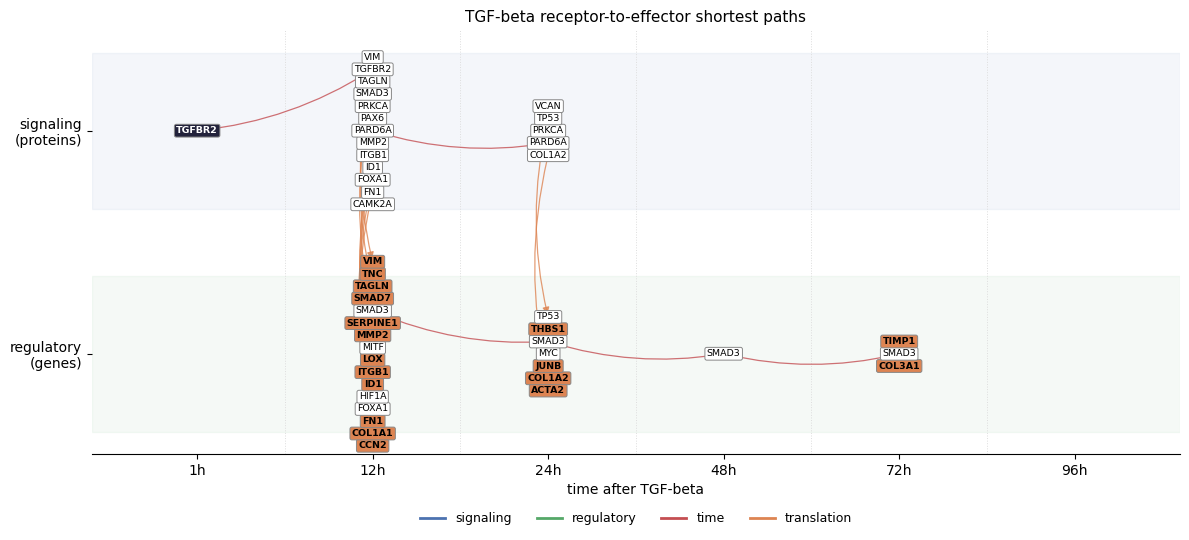

In [16]:
COLOURS = {
    'signaling': '#4c72b0',
    'regulatory': '#55a868',
    'coupling_time': '#c44e52',
    'coupling_translation': '#dd8452',
}
BAND = {'regulatory': 0, 'signaling': 1}

nodes = sorted({v for path in paths.values() for v in path})
arcs = sorted({edge for path in paths.values() for edge in zip(path, path[1:], strict=False)})
endpoints = {path[-1] for path in paths.values()}
arc_kind = {(a, b): flow.es[flow.get_eid(a, b)]['edge_kind'] for a, b in arcs}

slots = {}
for v in nodes:
    mechanism, layer = names[v][1]
    slot = (mechanism, layer)
    rank = slots.setdefault(slot, {})
    rank[v] = len(rank)

pos = {}
for v in nodes:
    mechanism, layer = names[v][1]
    k = slots[(mechanism, layer)][v]
    n = len(slots[(mechanism, layer)])
    pos[v] = (TIMES.index(layer), BAND[mechanism] + (k - (n - 1) / 2) * 0.055)

fig, ax = plt.subplots(figsize=(12, 5.5))
for mechanism, y in BAND.items():
    ax.axhspan(y - 0.35, y + 0.35, color=COLOURS[mechanism], alpha=0.06)
for x in np.arange(len(TIMES) - 1) + 0.5:
    ax.axvline(x, color='#dddddd', lw=0.7, ls=':')

for a, b in arcs:
    (x0, y0), (x1, y1) = pos[a], pos[b]
    ax.annotate(
        '',
        (x1, y1),
        (x0, y0),
        arrowprops={
            'arrowstyle': '-|>',
            'lw': 0.9,
            'color': COLOURS.get(arc_kind[(a, b)], '#999999'),
            'alpha': 0.8,
            'connectionstyle': 'arc3,rad=0.12',
        },
    )

for v in nodes:
    symbol = names[v][0].split(':', 1)[1]
    style = (
        ('#22223b', 'white', 'bold')
        if v in seeds
        else ('#dd8452', 'black', 'bold')
        if v in endpoints
        else ('white', 'black', 'normal')
    )
    ax.text(
        *pos[v],
        symbol,
        ha='center',
        va='center',
        fontsize=6.8,
        color=style[1],
        fontweight=style[2],
        bbox={'boxstyle': 'round,pad=0.2', 'fc': style[0], 'ec': '#888888', 'lw': 0.7},
    )

ax.set(
    xticks=range(len(TIMES)),
    xticklabels=TIMES,
    yticks=[0, 1],
    yticklabels=['regulatory\n(genes)', 'signaling\n(proteins)'],
    xlim=(-0.6, len(TIMES) - 0.4),
    ylim=(-0.45, 1.45),
    xlabel='time after TGF-beta',
)
ax.set_title('TGF-beta receptor-to-effector shortest paths', fontsize=11)
ax.legend(
    [plt.Line2D([], [], color=c, lw=2) for c in COLOURS.values()],
    [k.replace('coupling_', '') for k in COLOURS],
    ncol=4,
    frameon=False,
    loc='upper center',
    bbox_to_anchor=(0.5, -0.11),
    fontsize=9,
)
for spine in ('top', 'right', 'left'):
    ax.spines[spine].set_visible(False)
fig.tight_layout()
plt.show()

### The result goes back onto the graph

igraph computed it; AnnNet stores it. The arrival layer and hop count are
written as ordinary vertex attributes, so they survive the snapshot and are
available to every later section — the round-trip at the end checks exactly
that.


In [17]:
flow_attrs = {}
for symbol in {n[0] for n in supra if n[0].startswith(('prot:', 'gene:'))}:
    mechanism = 'signaling' if symbol.startswith('prot:') else 'regulatory'
    hit = earliest(full, symbol.split(':', 1)[1], mechanism, symbol.split(':', 1)[0] + ':')
    if hit:
        flow_attrs[symbol] = {'tgfb_first_layer': hit[0], 'tgfb_hops': int(hit[1])}

anet.attrs.update('nodes', flow_attrs)
anet.history.snapshot('after_signal_flow')
print(f'{len(flow_attrs):,} entities carry a TGF-β arrival time')
(
    anet.attrs.table('nodes', derived=True)
    .filter(pl.col('tgfb_hops').is_not_null())
    .group_by('tgfb_first_layer')
    .len()
    .sort('tgfb_first_layer')
)

4,944 entities carry a TGF-β arrival time


tgfb_first_layer,len
str,u32
"""12h""",1017
"""1h""",4
"""24h""",825
"""48h""",978
"""72h""",594
"""96h""",1526


## Cytoscape path subnetwork

The Cytoscape view shows the union of the receptor-to-effector paths from the
previous section.


In [18]:
from annnet.utils import show_cytoscape

cx2 = an.to_cx2(
    anet, path=str(OUT / 'uc2.cx2'), export_name='UC2 response graph', hyperedges='skip'
)
print(f'whole graph CX2 : {len(cx2[4]["nodes"]):,} nodes')

path_anet = an.AnnNet(directed=True)
path_label, path_vertices = {}, []
for v in sorted(nodes):
    vid, (mechanism, layer) = names[v]
    symbol = vid.split(':', 1)[1]
    label = f'{symbol}|{mechanism}|{layer}'
    role = 'receptor' if v in seeds else 'effector' if v in endpoints else 'intermediate'
    path_label[v] = label
    path_vertices.append(
        {
            'node_id': label,
            'gene_symbol': symbol,
            'mechanism': mechanism,
            'time': layer,
            'role': role,
        }
    )
path_anet.add_nodes(path_vertices)
path_anet.add_edges(
    [
        {
            'edge_id': f'path:{i}',
            'source': path_label[a],
            'target': path_label[b],
            'edge_kind': arc_kind[(a, b)],
            'weight': 1.0,
        }
        for i, (a, b) in enumerate(sorted(arcs, key=lambda e: (path_label[e[0]], path_label[e[1]])))
    ],
    default_edge_directed=True,
)
path_cx2 = an.to_cx2(
    path_anet,
    path=str(OUT / 'tgfb_effector_paths.cx2'),
    export_name='TGF-beta receptor-to-effector paths',
    hyperedges='skip',
)
print(f'path subnetwork : {len(path_cx2[4]["nodes"]):,} nodes, {len(path_cx2[5]["edges"]):,} edges')
show_cytoscape(
    path_anet, hyperedges='skip', inline=True, export_name='TGF-beta receptor-to-effector paths'
)

whole graph CX2 : 19,580 nodes
path subnetwork : 46 nodes, 45 edges


## Late-response forecasting

Using only layers through 72h, the model ranks regulatory genes that newly join
the response at 96h.


In [19]:
import torch
from sklearn.metrics import average_precision_score, roc_auc_score
from torch_geometric.nn import SAGEConv

In [20]:
INPUT_TIMES = TIMES[:-1]
TARGET_TIME = TIMES[-1]
HIDDEN, LR, EPOCHS, TEST_FRAC = 64, 1e-2, 60, 0.30

window = anet.layers.layer_union(
    [(m, t) for m in MECHANISMS for t in INPUT_TIMES],
    include_inter=True,  # translation coupling: two different vertex ids, so `inter`
    include_coupling=True,  # time coupling: one vertex id across layers, so `coupling`
)
inside = E[E.edge_id.isin(window['edges']) & E.edge_kind.isin(FAMILIES)]
inside = inside[inside.src_time.isin(INPUT_TIMES) & inside.tgt_time.isin(INPUT_TIMES)]
print(
    f'layer_union: {len(window["nodes"]):,} nodes, {len(window["edges"]):,} edges;'
    f' {len(window["edges"]) - len(inside):,} dropped as crossing the 72h boundary'
)

node_index, family_edges = {}, {k: [] for k in FAMILIES}
for r in inside.itertuples():
    src = node_index.setdefault((r.src, r.src_mech, r.src_time), len(node_index))
    tgt = node_index.setdefault((r.tgt, r.tgt_mech, r.tgt_time), len(node_index))
    family_edges[r.edge_kind].append((src, tgt))

position = {t: i / (len(INPUT_TIMES) - 1) for i, t in enumerate(INPUT_TIMES)}
features = torch.tensor(
    [
        [
            float(mechanism == 'signaling'),
            float(mechanism == 'regulatory'),
            position[t],
            float(vid.split(':', 1)[1] in tf_symbols),
            float(logfc_at.get((vid.split(':', 1)[1], t), 0.0)),
        ]
        for vid, mechanism, t in node_index
    ],
    dtype=torch.float32,
)

# Each candidate gene is read out at its latest regulatory supra-node <= 72h.
latest_node = {}
for (vid, mechanism, t), i in node_index.items():
    symbol = vid.removeprefix('gene:')
    if mechanism == 'regulatory' and (
        symbol not in latest_node or position[t] > position[latest_node[symbol][1]]
    ):
        latest_node[symbol] = (i, t)

candidates = sorted(latest_node)
y = np.array(
    [
        int(s in responsive_at[TARGET_TIME] and s not in responsive_at[INPUT_TIMES[-1]])
        for s in candidates
    ]
)
readout = torch.tensor([latest_node[s][0] for s in candidates], dtype=torch.long)

print(f'supra-nodes {len(node_index):,} | candidate genes {len(candidates):,}')
print(f'{TARGET_TIME}-specific positives: {y.sum()} ({y.mean():.1%} base rate)')
print('edge families:', {k: len(v) for k, v in family_edges.items()})

layer_union: 4,013 nodes, 31,655 edges; 2,814 dropped as crossing the 72h boundary
supra-nodes 9,301 | candidate genes 1,543
96h-specific positives: 108 (7.0% base rate)
edge families: {'signaling': 15308, 'regulatory': 6570, 'coupling_translation': 2133, 'coupling_time': 4830}


### Model and priority table


In [21]:
UNDIRECTED = {'signaling', 'regulatory', 'coupling_translation'}


def edge_index(families):
    forward = [e for k in families for e in family_edges[k]]
    index = torch.tensor(forward, dtype=torch.long).t().contiguous()
    reverse = [e for k in families if k in UNDIRECTED for e in family_edges[k]]
    return torch.cat([index, torch.tensor(reverse, dtype=torch.long).t().flip(0)], dim=1)


class Forecaster(torch.nn.Module):
    def __init__(self, in_dim, hidden):
        super().__init__()
        self.conv1 = SAGEConv(in_dim, hidden)
        self.conv2 = SAGEConv(hidden, hidden)
        self.head = torch.nn.Linear(hidden, 1)

    def forward(self, x, index):
        x = self.conv1(x, index).relu()
        return self.head(self.conv2(x, index).relu()).squeeze(-1)


rng = np.random.default_rng(SEED)
test_idx = rng.choice(len(candidates), int(TEST_FRAC * len(candidates)), replace=False)
train_idx = np.setdiff1d(np.arange(len(candidates)), test_idx)
target = torch.tensor(y, dtype=torch.float32)
index = edge_index(FAMILIES)

model = Forecaster(features.size(1), HIDDEN)
optimizer = torch.optim.Adam(model.parameters(), lr=LR)
for _ in range(EPOCHS):
    optimizer.zero_grad()
    loss = torch.nn.functional.binary_cross_entropy_with_logits(
        model(features, index)[readout[train_idx]], target[train_idx]
    )
    loss.backward()
    optimizer.step()

with torch.no_grad():
    scores = torch.sigmoid(model(features, index)[readout]).numpy()
print(
    f'AUROC={roc_auc_score(y[test_idx], scores[test_idx]):.3f}  '
    f'AP={average_precision_score(y[test_idx], scores[test_idx]):.3f}'
)

priority_rows = []
for gene, score, label in zip(candidates, scores, y.astype(bool), strict=False):
    hit = flow_attrs.get(f'gene:{gene}', {})
    priority_rows.append(
        {
            'gene': gene,
            'score': score,
            'is_new_96h_responder': label,
            'latest_input_layer': latest_node[gene][1],
            'tgfb_first_layer': hit.get('tgfb_first_layer'),
            'tgfb_hops': hit.get('tgfb_hops'),
        }
    )
priority = (
    pd.DataFrame(priority_rows)
    .iloc[test_idx]
    .sort_values('score', ascending=False, ignore_index=True)
)
priority.head(15)

AUROC=0.956  AP=0.475


,gene,score,is_new_96h_responder,latest_input_layer,tgfb_first_layer,tgfb_hops
0,BACH1,0.474527,True,24h,24h,7.0
1,NCOA3,0.467743,True,48h,48h,8.0
2,MXI1,0.467102,False,24h,None,NaN
3,HMGCR,0.460829,False,24h,24h,7.0
4,DFFA,0.459496,False,24h,24h,6.0
5,CD63,0.459167,False,24h,24h,6.0
6,OGG1,0.454197,False,24h,24h,7.0
7,RIMS2,0.452184,True,48h,48h,7.0
8,PSMB10,0.451155,False,48h,48h,9.0
9,GULP1,0.450894,False,48h,48h,7.0


## Save and read the graph

The final `.annnet` file preserves the graph, slices, hyperedges, arrival
attributes and build history.


In [22]:
anet.history.snapshot('final')
anet.write(str(SNAPSHOT), overwrite=True)
reloaded_anet = an.AnnNet.read(str(SNAPSHOT))

print(f'{SNAPSHOT.name} ({SNAPSHOT.stat().st_size / 1e6:.1f} MB)')
print(
    f'|V|={reloaded_anet.global_count("nodes"):,} |E|={reloaded_anet.global_count("edges"):,}'
    f' aspects={reloaded_anet.layers.list_aspects()} slices={len(reloaded_anet.slices.list()):,}'
)
print(f'hyperedges  : {len(reloaded_anet.hyperedge_definitions):,}')
back = reloaded_anet.attrs.table('nodes', derived=True).filter(pl.col('tgfb_hops').is_not_null())
print(f'arrival times survived: {len(back):,} / {len(flow_attrs):,}')
print(f'attribute columns: {sorted(reloaded_anet.attrs.table("nodes", derived=True).columns)}')

uc2.annnet (3.7 MB)
|V|=19,580 |E|=63,729 aspects=('mechanism', 'time') slices=20
hyperedges  : 16,417
arrival times survived: 4,944 / 4,944
attribute columns: ['boundary_condition', 'compartment', 'constant', 'gene_symbol', 'has_only_substance_units', 'initial_concentration', 'kind', 'meta_id', 'name', 'node_id', 'sbo_term', 'tgfb_first_layer', 'tgfb_hops']


## Scope

This is a software case study on a real biological substrate. Shortest paths are
routes to inspect, not mechanisms by themselves. GNN scores are late-response
priorities, not causal claims.

The 0-hop responsive restriction keeps time informative: a node-layer exists only
where the entity is differential, and an intra-layer edge only where both
endpoints are differential. Translation coupling is undirected because a gene and
its protein are two readings of the same entity; time coupling is directed
because time has an order.
